# Get the dataset

In [41]:
#Import libraries Used :-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
df = pd.read_csv('/content/Unemployment in India.csv')
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


Understanding the dataset:

In [43]:
#Check the number of rows and columns :-
df.shape

(768, 7)

In [44]:
#Check all column names :-
df.columns

Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')

In [45]:
#Check dataset information :-
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [46]:
#Statistical Summary :-
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [47]:
#Check missing values :-
df.isnull().sum()

,0
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


# Data Cleaning:

In [48]:
#Check and clean columns :-
df.columns = df.columns.str.strip()  #Removed extra spaces from column names
df.columns

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')

In [49]:
#Clean extra spaces from text values :-
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()
print("Text data cleaned successfully!")

Text data cleaned successfully!


In [50]:
#check duplicate records :-
print("Duplicate rows :-", df.duplicated().sum())

Duplicate rows :- 27


In [51]:
#Drop duplicate rows :-
df = df.drop_duplicates().copy()
print("Duplicate rows dropped successfully!")

Duplicate rows dropped successfully!


In [52]:
#Handle missing values :-
df.replace(r'^\s*$', np.nan, regex=True, inplace=True)

# Convert numerical columns into numeric format
numeric_columns = [
    'Estimated Unemployment Rate (%)',
    'Estimated Employed',
    'Estimated Labour Participation Rate (%)'
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

df.isnull().sum()  #check missing values

,0
Region,1
Date,1
Frequency,1
Estimated Unemployment Rate (%),1
Estimated Employed,1
Estimated Labour Participation Rate (%),1
Area,1


In [53]:
#Calculate percentage of missing values:-
missing_percentage = (df.isnull().sum() / len(df) * 100).round(2)
missing_percentage

,0
Region,0.13
Date,0.13
Frequency,0.13
Estimated Unemployment Rate (%),0.13
Estimated Employed,0.13
Estimated Labour Participation Rate (%),0.13
Area,0.13


In [54]:
#Check the cleaned dataset :-
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [55]:
#Find the missing row:-
missing_rows = df[df.isnull().any(axis=1)]
missing_rows

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [56]:
#Check row completely empty:-
print("Completely empty rows :-", df.isnull().all(axis=1).sum())

Completely empty rows :- 1


In [57]:
#Remove completely empty rows :-
df = df.dropna(how='all').copy()
print("Missing values after removing empty rows:")
print(df.isnull().sum())

Missing values after removing empty rows:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


In [58]:
#Verify completely empty rows after cleaning :-
print("Remaining completely empty rows:", df.isnull().all(axis=1).sum())

Remaining completely empty rows: 0


Data Cleaning completed

# Exploratory Data Analysis:

In [59]:
#Convert Dataframe into datetime format :-
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')

# Check whether any date could not be converted
print("Invalid dates:", df['Date'].isna().sum())

Invalid dates: 0


In [60]:
#Create Year and Month Columns
# Extract Year and Month
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

# Display the first few rows
df[['Date', 'Year', 'Month']].head()

,Date,Year,Month
0,2019-05-31,2019,5
1,2019-06-30,2019,6
2,2019-07-31,2019,7
3,2019-08-31,2019,8
4,2019-09-30,2019,9


In [61]:
#Calculate average unemployment rate :-
avg_unemployment = df['Estimated Unemployment Rate (%)'].mean()
print("Average unemployment rate :-", round(avg_unemployment, 2), "%")

Average unemployment rate :- 11.79 %


In [62]:
#Find the highest unemployment rate:-
highest = df.loc[df['Estimated Unemployment Rate (%)'].idxmax()]
highest

,627
Region,Puducherry
Date,2020-04-30 00:00:00
Frequency,Monthly
Estimated Unemployment Rate (%),76.74
Estimated Employed,68122.0
Estimated Labour Participation Rate (%),35.54
Area,Urban
Year,2020
Month,4


# DATA VISUALIZATION:

In [63]:
#Unemployment trend over time :-
#Average unemployment rate for each date
date_unemployment = df.groupby('Date')['Estimated Unemployment Rate (%)'].mean().sort_index()
date_unemployment.head()

,Estimated Unemployment Rate (%)
Date,
2019-05-31,8.874259
2019-06-30,9.303333
2019-07-31,9.033889
2019-08-31,9.637925
2019-09-30,9.051731


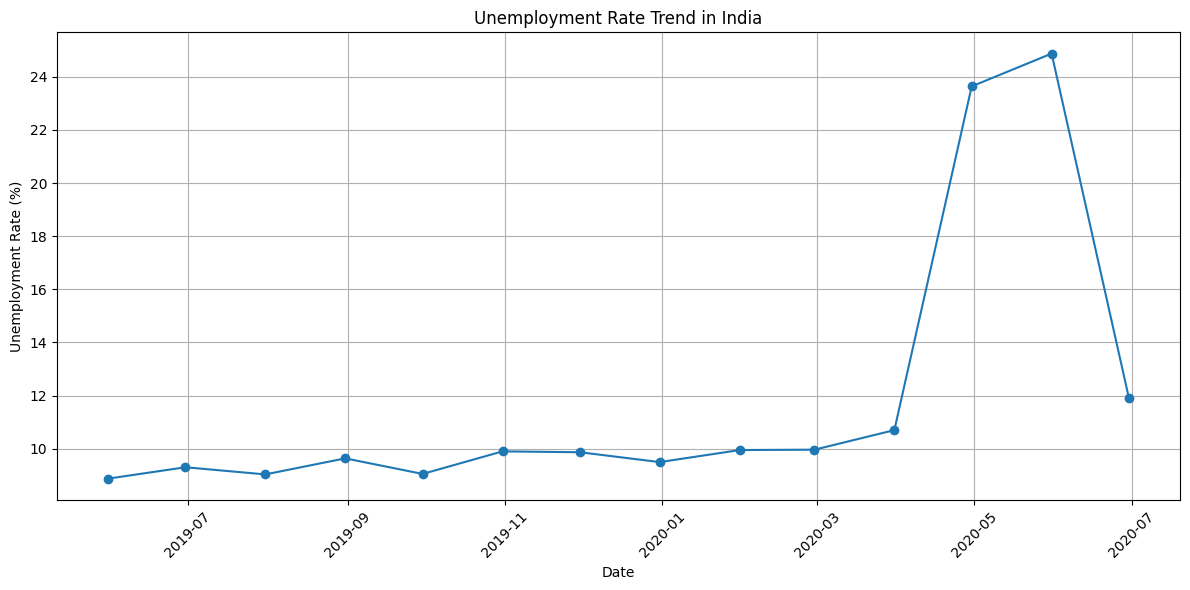

In [64]:
#Graph Plot:-
plt.figure(figsize=(12, 6))
plt.plot(
    date_unemployment.index,
    date_unemployment.values,
    marker='o'
)
plt.title('Unemployment Rate Trend in India')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [65]:
#StateWise unemployment analysis :-
#States having highest unemployment
state_unemployment = (
    df.groupby('Region')['Estimated Unemployment Rate (%)']
    .mean()
    .sort_values(ascending=False)
)
state_unemployment

,Estimated Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


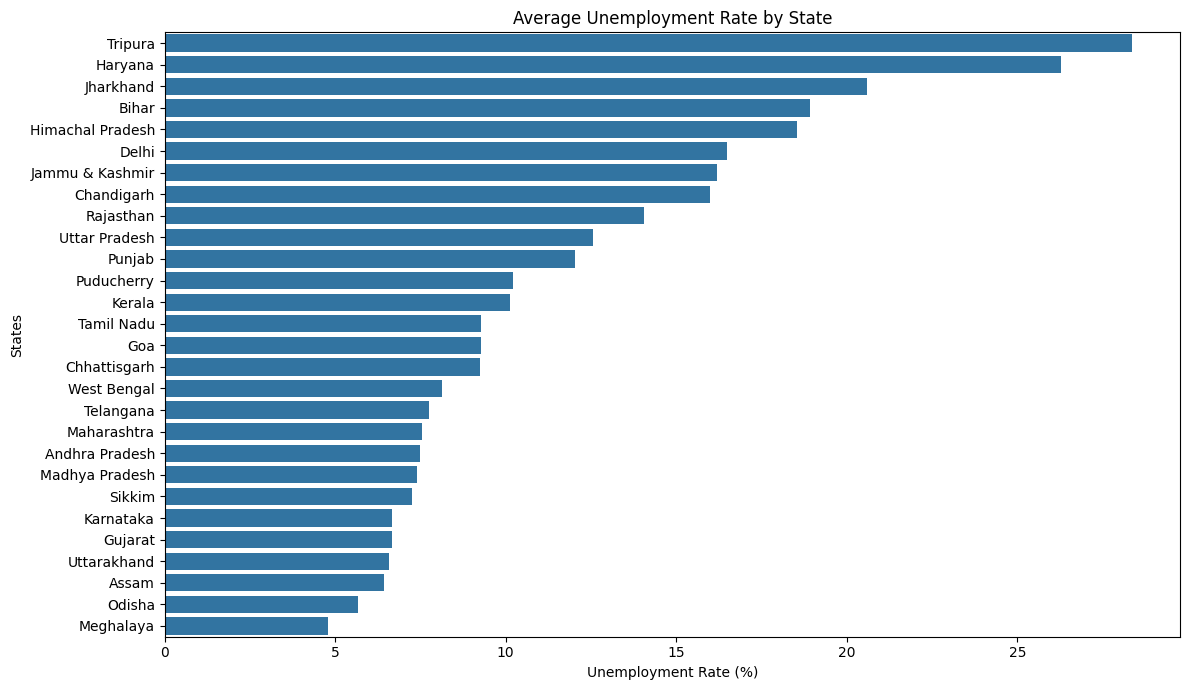

In [66]:
#GRAPH PLOT :-
plt.figure(figsize=(12, 7))
sns.barplot(
    x=state_unemployment.values,
    y=state_unemployment.index
)
plt.title('Average Unemployment Rate by State')
plt.xlabel('Unemployment Rate (%)')
plt.ylabel('States')
plt.tight_layout()
plt.show()

In [67]:
#COVID-19 IMPACT ANALYSIS :-
#For this we use March 2020 as starting point
before_covid = df[df['Date'] < '2020-03-01']
during_covid = df[df['Date'] >= '2020-03-01']

before_avg = before_covid['Estimated Unemployment Rate (%)'].mean()
during_avg = during_covid['Estimated Unemployment Rate (%)'].mean()

print("Before COVID:", round(before_avg, 2), "%")
print("During COVID:", round(during_avg, 2), "%")

Before COVID: 9.51 %
During COVID: 17.77 %


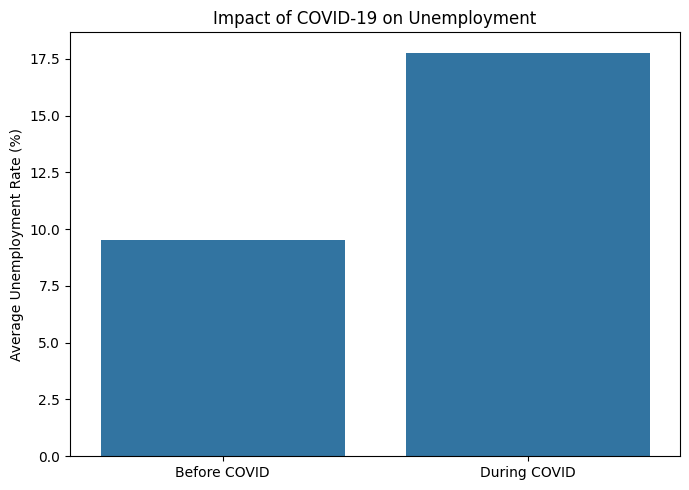

In [68]:
#Comparison Graph :-
plt.figure(figsize=(7, 5))
sns.barplot(
    x=['Before COVID', 'During COVID'],
    y=[before_avg, during_avg]
)
plt.title('Impact of COVID-19 on Unemployment')
plt.ylabel('Average Unemployment Rate (%)')
plt.tight_layout()
plt.show()

# RURAL vs URBAN UNEMPLOYMENT:

In [69]:
#Comparing unemployment between rural and urban
area_unemployment = df.groupby('Area')['Estimated Unemployment Rate (%)'].mean()
area_unemployment

,Estimated Unemployment Rate (%)
Area,
Rural,10.324791
Urban,13.166614


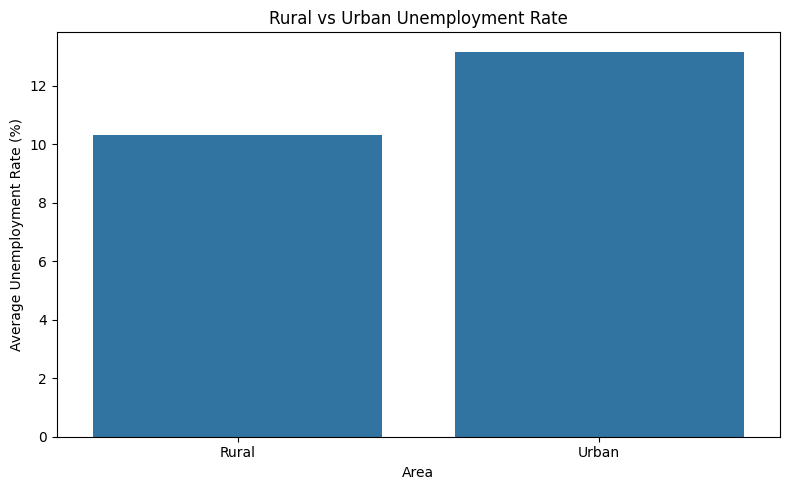

In [70]:
#COMPARISON GRAPH PLOT :-
plt.figure(figsize=(8, 5))
sns.barplot(
    x=area_unemployment.index,
    y=area_unemployment.values
)
plt.title('Rural vs Urban Unemployment Rate')
plt.xlabel('Area')
plt.ylabel('Average Unemployment Rate (%)')
plt.tight_layout()
plt.show()

In [71]:
#COVID-19 IMPACT ANALYSIS :- Unemployment before COVID-19 and during COVID-19 by area
df_covid = df.copy()
df_covid['COVID_Period'] = np.where(
    df_covid['Date'] < '2020-03-01',
    'Before COVID',
    'During COVID'
)

covid_area_comparison = (
    df_covid.groupby(['Area', 'COVID_Period'])['Estimated Unemployment Rate (%)']
    .mean()
    .reset_index()
)
covid_area_comparison

,Area,COVID_Period,Estimated Unemployment Rate (%)
0,Rural,Before COVID,8.094808
1,Rural,During COVID,16.181313
2,Urban,Before COVID,10.842246
3,Urban,During COVID,19.276381


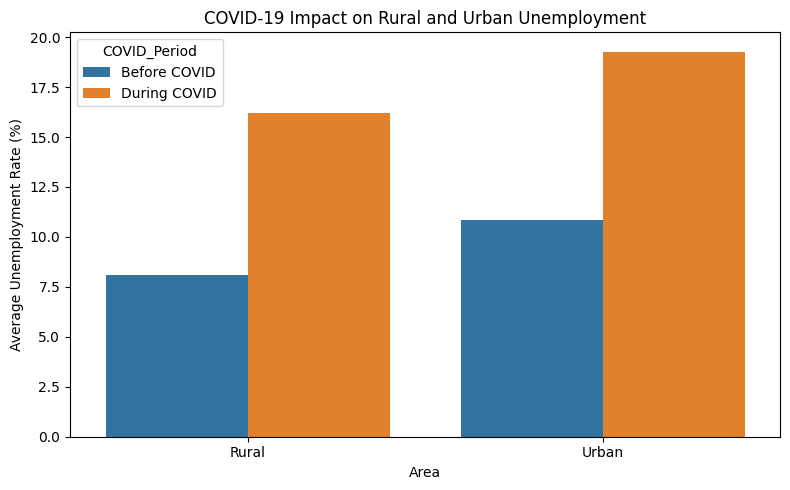

In [72]:
#COMPARISON GRAPH :-
plt.figure(figsize=(8, 5))
sns.barplot(
    data=covid_area_comparison,
    x='Area',
    y='Estimated Unemployment Rate (%)',
    hue='COVID_Period'
)
plt.title('COVID-19 Impact on Rural and Urban Unemployment')
plt.xlabel('Area')
plt.ylabel('Average Unemployment Rate (%)')
plt.tight_layout()
plt.show()

# Final Analysis and Insights

In [73]:
#Identify Important Findings:-
print("===== UNEMPLOYMENT ANALYSIS =====")
print("Average Unemployment Rate :-", round(df['Estimated Unemployment Rate (%)'].mean(), 2), "%")
print("\nHighest Unemployment State :-", state_unemployment.idxmax())
print("\nLowest Unemployment State :-", state_unemployment.idxmin())
print("\nRural vs Urban Analysis :-")
print(area_unemployment)
print("\nCOVID-19 Comparison :-")
print("Before COVID:", round(before_avg, 2), "%")
print("During COVID:", round(during_avg, 2), "%")

===== UNEMPLOYMENT ANALYSIS =====
Average Unemployment Rate :- 11.79 %

Highest Unemployment State :- Tripura

Lowest Unemployment State :- Meghalaya

Rural vs Urban Analysis :-
Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64

COVID-19 Comparison :-
Before COVID: 9.51 %
During COVID: 17.77 %


In [74]:
#Analyse Monthy Patterns :-
monthly_trends = df.groupby('Month')['Estimated Unemployment Rate (%)'].mean()
monthly_trends

,Estimated Unemployment Rate (%)
Month,
1,9.950755
2,9.964717
3,10.700577
4,23.641569
5,16.646190
6,10.553462
7,9.033889
8,9.637925
9,9.051731


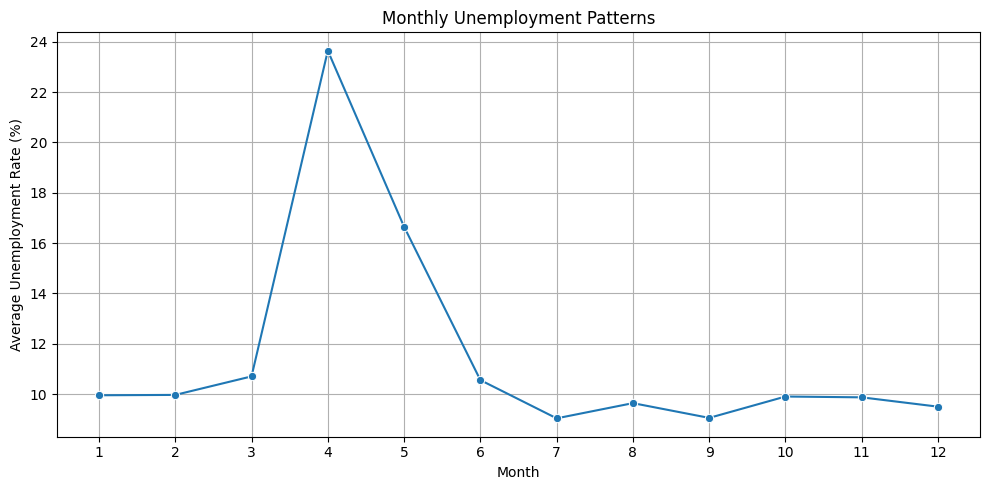

In [75]:
#Graph Plot :-
plt.figure(figsize=(10, 5))
sns.lineplot(
    x=monthly_trends.index,
    y=monthly_trends.values,
    marker='o'
)
plt.title('Monthly Unemployment Patterns')
plt.xlabel('Month')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

# Conclusion – Unemployment Analysis in India

This project analyzes unemployment trends in India using Python and data analysis techniques.

The dataset was cleaned by removing completely empty records and checking for missing values and duplicates.

Exploratory Data Analysis was performed to understand unemployment patterns across different states and areas.

The visualizations revealed changes in unemployment during the COVID-19 period. State-wise analysis also highlighted differences in unemployment rates across regions.

Rural and urban unemployment rates were compared to understand differences in employment conditions.

### Key Learning Outcomes

- Learned data cleaning using Pandas.
- Performed Exploratory Data Analysis (EDA).
- Used Matplotlib and Seaborn for visualization.
- Analyzed unemployment trends.
- Compared regional unemployment rates.
- Investigated changes during the COVID-19 period.

### Final Outcome

This project demonstrates how Python and data analysis can help identify employment patterns and generate insights that may support economic and social policy discussions.